# 03 · Modelado y evaluación
**Caso:** Sistema de recomendación de productos · Nexus Retail SpA

**Objetivo:** entrenar un modelo que, para cada usuario, ordene los productos según su probabilidad de compra en los próximos 90 días, y **demostrar si aporta algo frente a lo más simple** (recomendar los más vendidos).

**Cómo se evalúa**
- Los hiperparámetros se eligen con los dos primeros cortes y el **tercero**, por **nDCG@8 rankeando todo el catálogo** (`ranking_seleccion.pkl`).
- El modelo se entrena con los 3 primeros cortes (`entrenamiento.pkl`).
- Se evalúa en el **último corte**, que el modelo no vio, rankeando **todo el catálogo** para cada usuario (`ranking_validacion.pkl`), sin lo ya comprado.
- Métricas: **MAP@K** y **nDCG@K** (más Hit Rate, Recall y Precision), con K = 4 y 8 (el caso pide entre 4 y 8 recomendaciones por slot, RF1).
- Siempre frente a baselines: aleatorio, **más vendidos** (el criterio del RNF3) y una regla simple de popularidad por categoría favorita.

**Contenido:** 1 Carga · 2 Métricas · 3 Baselines · 4 Modelos y selección de hiperparámetros · 5 Evaluación final · 6 Análisis (segmentos, cola larga, importancia, explicaciones) · 7 Modelo final y entregables · 8 Conclusiones

## 1. Configuración y carga

In [1]:
import os
import warnings
from pathlib import Path
from itertools import product

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
KS = (4, 8)                 # recomendaciones por slot (RF1: entre 4 y 8)
K_CURVA = 20                # para las curvas métrica-vs-K
N_BOOT = 1000               # remuestreos del bootstrap sobre usuarios


def resolver_out_dir():
    # Carpeta de procesados del notebook 02 (variable DATA_OUT_DIR o ubicaciones habituales).
    candidatos = [Path(os.environ["DATA_OUT_DIR"])] if "DATA_OUT_DIR" in os.environ else []
    candidatos += [Path("datos/procesados"), Path("data/procesado"),
                   Path("..") / "datos" / "procesados", Path("..") / "data" / "procesado"]
    for c in candidatos:
        if (c / "entrenamiento.pkl").exists():
            return c.resolve()
    raise FileNotFoundError("No se encontró entrenamiento.pkl. Ejecuta primero 02_preparacion_datos_v2.ipynb. "
                            "Buscado en: " + ", ".join(str(c) for c in candidatos))


OUT_DIR = resolver_out_dir()
MODEL_DIR = OUT_DIR.parent / "modelos" if OUT_DIR.name == "procesados" else OUT_DIR / "modelo"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

entrenamiento = joblib.load(OUT_DIR / "entrenamiento.pkl")
validacion = joblib.load(OUT_DIR / "validacion.pkl")
ranking = joblib.load(OUT_DIR / "ranking_validacion.pkl")
if not (OUT_DIR / "ranking_seleccion.pkl").exists():
    raise FileNotFoundError("No se encontró ranking_seleccion.pkl. Vuelve a ejecutar 02_limpieza.ipynb (versión con grid de selección).")
ranking_seleccion = joblib.load(OUT_DIR / "ranking_seleccion.pkl")
metadatos = joblib.load(OUT_DIR / "metadatos.pkl")
sku_recomendables = set(joblib.load(OUT_DIR / "sku_recomendables.pkl"))
productos = pd.read_csv(OUT_DIR / "productos_limpio.csv")

FEATURES = metadatos["features"]
POP_ALPHA = metadatos["pop_alpha"]
EPS_POP = 1e-3                               # el mismo +1e-3 que usó el notebook 02 al muestrear negativos
COLS_CAT = [c for c in FEATURES if entrenamiento[c].dtype == object or str(entrenamiento[c].dtype) in ("string", "str", "category")]
COLS_NUM = [c for c in FEATURES if c not in COLS_CAT]

print(f"Carpeta de procesados: {OUT_DIR}")
print(f"Entrenamiento: {len(entrenamiento):,} filas ({int(entrenamiento['compra'].sum()):,} positivos) · "
      f"cortes: {sorted(entrenamiento['corte'].dt.date.unique())}")
print(f"Validación (muestreo 4:1): {len(validacion):,} filas · corte {validacion['corte'].iloc[0].date()}")
print(f"Ranking de validación: {len(ranking):,} filas · {ranking['usuario_id'].nunique():,} usuarios · "
      f"{ranking['sku'].nunique():,} SKU candidatos · {int(ranking['compra'].sum()):,} compras reales")
print(f"Ranking de selección (tercer corte): {len(ranking_seleccion):,} filas · {ranking_seleccion['usuario_id'].nunique():,} usuarios · "
      f"{int(ranking_seleccion['compra'].sum()):,} compras reales")
print(f"Predictores ({len(FEATURES)}): categóricos {COLS_CAT} · numéricos {len(COLS_NUM)}")

Carpeta de procesados: C:\Users\Gabo\Documents\modelo-nexus arquitectura\modelo-nexus\datos\procesados
Entrenamiento: 13,400 filas (2,680 positivos) · cortes: [datetime.date(2025, 8, 6), datetime.date(2025, 11, 4), datetime.date(2026, 2, 2)]
Validación (muestreo 4:1): 4,725 filas · corte 2026-05-03
Ranking de validación: 959,200 filas · 641 usuarios · 1,500 SKU candidatos · 945 compras reales
Ranking de selección (tercer corte): 943,098 filas · 640 usuarios · 928 compras reales
Predictores (25): categóricos ['region', 'canal_captacion', 'categoria', 'marca'] · numéricos 21


## 2. Métricas de ranking
Para cada usuario se ordenan los SKU candidatos por puntaje y se miran los primeros K. Lo relevante son las **compras reales** del usuario en la ventana de validación.

| Métrica | Qué mide |
|---|---|
| **Hit Rate@K** | % de usuarios con al menos una compra real entre sus K recomendaciones |
| **Precision@K** | Fracción de las K recomendaciones que fueron compradas |
| **Recall@K** | Fracción de las compras reales que quedaron entre las K |
| **MAP@K** | Promedio de la precisión en cada acierto: premia acertar *y* hacerlo arriba |
| **nDCG@K** | Cada acierto vale más cuanto más arriba está (descuento logarítmico) |

*Desempates:* a igual puntaje se ordena por `sku` (determinista). *Usuarios evaluados:* solo los que tienen al menos una compra real entre los candidatos de la vista evaluada.

In [2]:
def metricas_por_usuario(df, score, ks=KS, solo_recomendables=False):
    # Devuelve {K: DataFrame(usuario -> métricas)} para un vector de puntajes alineado con df.
    d = df[["usuario_id", "sku", "compra", "recomendable"]].copy()
    d["score"] = np.asarray(score, dtype=float)
    if solo_recomendables:
        d = d[d["recomendable"]]
    n_rel = d.groupby("usuario_id")["compra"].sum()
    evaluados = n_rel[n_rel > 0].index
    n_rel = n_rel.loc[evaluados]
    d = d[d["usuario_id"].isin(evaluados)]
    d = d.sort_values(["usuario_id", "score", "sku"], ascending=[True, False, True], kind="mergesort")
    d["rank"] = d.groupby("usuario_id").cumcount() + 1
    kmax = max(ks)
    d = d[d["rank"] <= kmax].copy()
    d["hits_cum"] = d.groupby("usuario_id")["compra"].cumsum()
    d["prec_rank"] = d["hits_cum"] / d["rank"]
    d["dcg_term"] = d["compra"] / np.log2(d["rank"] + 1)
    idcg_tabla = np.cumsum(1.0 / np.log2(np.arange(2, kmax + 2)))     # idcg_tabla[m-1] = IDCG con m relevantes

    res = {}
    for K in ks:
        t = d[d["rank"] <= K]
        g = t.groupby("usuario_id")
        hits = g["compra"].sum().reindex(evaluados).fillna(0)
        ap_num = (t["prec_rank"] * t["compra"]).groupby(t["usuario_id"]).sum().reindex(evaluados).fillna(0)
        dcg = g["dcg_term"].sum().reindex(evaluados).fillna(0)
        n = n_rel.to_numpy()
        res[K] = pd.DataFrame({
            "hit_rate": (hits > 0).astype(float).to_numpy(),
            "precision": (hits / K).to_numpy(),
            "recall": (hits / n_rel).to_numpy(),
            "map": (ap_num / np.minimum(n_rel, K)).to_numpy(),
            "ndcg": (dcg / idcg_tabla[np.minimum(n, K) - 1]).to_numpy(),
        }, index=evaluados)
    return res


def resumen(res_por_modelo, ks=KS):
    filas = []
    for nombre, res in res_por_modelo.items():
        for K in ks:
            m = res[K].mean()
            filas.append({"modelo": nombre, "K": K, "usuarios": len(res[K]), "MAP": m["map"], "nDCG": m["ndcg"],
                          "HitRate": m["hit_rate"], "Recall": m["recall"], "Precision": m["precision"]})
    return pd.DataFrame(filas)


# Verificación con el ejemplo del texto: compró B y D; el modelo ordena [A, B, C, D, E].
_ej = pd.DataFrame({"usuario_id": ["u"] * 5, "sku": list("ABCDE"), "compra": [0, 1, 0, 1, 0],
                    "recomendable": True})
_r = metricas_por_usuario(_ej, [5, 4, 3, 2, 1], ks=(5,))[5].iloc[0]
assert abs(_r["map"] - 0.5) < 1e-9 and abs(_r["precision"] - 0.4) < 1e-9
assert abs(_r["ndcg"] - (1 / np.log2(3) + 1 / np.log2(5)) / (1 + 1 / np.log2(3))) < 1e-9
print(f"[PASS] métricas verificadas con el ejemplo: MAP@5 = {_r['map']:.2f} · Precision@5 = {_r['precision']:.2f} · nDCG@5 = {_r['ndcg']:.3f}")

[PASS] métricas verificadas con el ejemplo: MAP@5 = 0.50 · Precision@5 = 0.40 · nDCG@5 = 0.651


## 3. Baselines
Cualquier modelo debe superarlos para justificar su existencia:
1. **Aleatorio:** el piso.
2. **Más vendidos:** ordena por compradores distintos antes del corte. Es lo que el sitio mostraría si falla el recomendador (RNF3).
3. **Popularidad × categoría favorita:** una regla simple y personalizada (más vendidos de las categorías donde el usuario ya compra). Si el modelo no la supera, el aprendizaje automático no aporta sobre una regla.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
scores_baseline = {
    "Aleatorio": rng.random(len(ranking)),
    "Más vendidos": ranking["n_compradores"].to_numpy(float),
    "Popularidad × categoría": ranking["n_compradores"].to_numpy(float) * (ranking["afinidad_categoria"].to_numpy(float) + 0.05),
}
VISTAS = {"Todo el catálogo": False, "Solo SKU recomendables": True}

res = {vista: {nombre: metricas_por_usuario(ranking, s, solo_recomendables=flag)
               for nombre, s in scores_baseline.items()}
       for vista, flag in VISTAS.items()}

for vista in VISTAS:
    print(f"\n=== Baselines · {vista} ===")
    display(resumen(res[vista]).set_index(["modelo", "K"]))


=== Baselines · Todo el catálogo ===


usuarios    MAP   nDCG  HitRate  Recall  Precision
modelo                  K                                                    
Aleatorio               4       641 0.0028 0.0042   0.0094  0.0078     0.0023
                        8       641 0.0029 0.0045   0.0109  0.0086     0.0014
Más vendidos            4       641 0.0564 0.0793   0.1794  0.1112     0.0468
                        8       641 0.0709 0.1100   0.2808  0.1886     0.0386
Popularidad × categoría 4       641 0.1388 0.1726   0.2995  0.2327     0.0811
                        8       641 0.1630 0.2254   0.4680  0.3705     0.0659


=== Baselines · Solo SKU recomendables ===


usuarios    MAP   nDCG  HitRate  Recall  Precision
modelo                  K                                                    
Aleatorio               4       333 0.0038 0.0042   0.0060  0.0045     0.0015
                        8       333 0.0059 0.0093   0.0240  0.0190     0.0030
Más vendidos            4       333 0.1089 0.1405   0.2462  0.2117     0.0653
                        8       333 0.1427 0.2089   0.4264  0.3994     0.0593
Popularidad × categoría 4       333 0.2355 0.2842   0.4444  0.4047     0.1179
                        8       333 0.2660 0.3460   0.6096  0.5708     0.0845

## 4. Modelos
Dos modelos de propensión a compra, ambos sobre los mismos predictores:
- **Regresión logística** (interpretable): categóricas con one-hot, numéricas con `log1p` y estandarización.
- **Gradient boosting** (`HistGradientBoostingClassifier`): captura interacciones no lineales; maneja categóricas de forma nativa.

**Selección de hiperparámetros por tiempo.** Se entrena con los dos primeros cortes y se elige con el tercero (nunca con el de validación final). El criterio es **nDCG@8 rankeando todo el catálogo** (`ranking_seleccion`), con el mismo prior de popularidad que se usa en la evaluación final: es la métrica que realmente importa. *Average Precision* y AUC sobre los pares muestreados se muestran solo como diagnóstico, porque miden clasificación entre 1 positivo y 4 negativos, no calidad de ranking.

**Corrección por muestreo de negativos.** Como los negativos se muestrearon *proporcionalmente a la popularidad*, un clasificador entrenado así aprende `P(compra | x) / q(sku)`, donde `q` es la probabilidad de muestreo. Eso borra la popularidad del puntaje, y al rankear todo el catálogo se pierde un prior valioso. Se recupera sumando `log q(sku)` al log-odds:

`puntaje = log-odds del modelo + POP_ALPHA × log(compradores + 0,001)`

Se evalúa el modelo **con y sin** la corrección para mostrar su efecto.

In [4]:
def pipeline_logistica(C):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), COLS_CAT),
        ("num", Pipeline([("log", FunctionTransformer(np.log1p, validate=False)),
                          ("esc", StandardScaler())]), COLS_NUM),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE))])


def pipeline_boosting(learning_rate, max_leaf_nodes, l2_regularization, max_iter=150):
    pre = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), COLS_CAT),
    ], remainder="passthrough")
    clf = HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, l2_regularization=l2_regularization,
        max_iter=max_iter, categorical_features=list(range(len(COLS_CAT))), random_state=RANDOM_STATE)
    return Pipeline([("pre", pre), ("clf", clf)])


def log_prior_popularidad(df):
    # Corrección por el muestreo de negativos (ver arriba). También se usa en la sección 5.
    return POP_ALPHA * np.log(df["n_compradores"].to_numpy(float) + EPS_POP)


# Selección temporal: entrenar con los 2 primeros cortes y elegir con el tercero.
cortes_tr = sorted(entrenamiento["corte"].unique())
sel_train = entrenamiento[entrenamiento["corte"].isin(cortes_tr[:-1])]
sel_valid = entrenamiento[entrenamiento["corte"] == cortes_tr[-1]]
assert pd.Timestamp(ranking_seleccion["corte"].iloc[0]) == pd.Timestamp(cortes_tr[-1]), \
    "ranking_seleccion no corresponde al tercer corte"
print(f"Selección: entrena {len(sel_train):,} filas (cortes {[str(c)[:10] for c in cortes_tr[:-1]]}) · "
      f"se elige con el ranking de {ranking_seleccion['usuario_id'].nunique():,} usuarios del corte {str(cortes_tr[-1])[:10]}")

K_SEL = 8
prior_sel = log_prior_popularidad(ranking_seleccion)


def evaluar_candidato(modelo, nombre, params):
    # Criterio principal: nDCG@8 sobre el catálogo completo (con prior). AP/AUC de pares: solo diagnóstico.
    p_pares = modelo.decision_function(sel_valid[FEATURES])
    puntaje = modelo.decision_function(ranking_seleccion[FEATURES]) + prior_sel
    m = metricas_por_usuario(ranking_seleccion, puntaje, ks=(K_SEL,))[K_SEL].mean()
    return {"modelo": nombre, "params": params, "nDCG@8": m["ndcg"], "MAP@8": m["map"], "HitRate@8": m["hit_rate"],
            "AP (pares)": average_precision_score(sel_valid["compra"], p_pares),
            "AUC (pares)": roc_auc_score(sel_valid["compra"], p_pares)}


filas = []
for C_ in [0.01, 0.1, 1.0, 10.0]:
    m = pipeline_logistica(C_).fit(sel_train[FEATURES], sel_train["compra"])
    filas.append(evaluar_candidato(m, "logística", {"C": C_}))
for lr, leaves, l2 in product([0.05, 0.1], [8, 31], [0.0, 1.0]):
    m = pipeline_boosting(lr, leaves, l2).fit(sel_train[FEATURES], sel_train["compra"])
    filas.append(evaluar_candidato(m, "boosting", {"learning_rate": lr, "max_leaf_nodes": leaves, "l2_regularization": l2}))

busqueda = pd.DataFrame(filas).sort_values("nDCG@8", ascending=False).reset_index(drop=True)

# Referencia: la regla "Popularidad × categoría" en ese mismo corte (el modelo debería superarla también aquí)
regla_sel = ranking_seleccion["n_compradores"].to_numpy(float) * (ranking_seleccion["afinidad_categoria"].to_numpy(float) + 0.05)
ref = metricas_por_usuario(ranking_seleccion, regla_sel, ks=(K_SEL,))[K_SEL].mean()
print(f"Referencia en el corte de selección · Popularidad × categoría: nDCG@8 = {ref['ndcg']:.4f} · MAP@8 = {ref['map']:.4f}")
display(busqueda)
mejor = {nombre: busqueda[busqueda["modelo"] == nombre].iloc[0]["params"] for nombre in ["logística", "boosting"]}
print("Mejores hiperparámetros:", mejor)

Selección: entrena 8,760 filas (cortes ['2025-08-06', '2025-11-04']) · se elige con el ranking de 640 usuarios del corte 2026-02-02
Referencia en el corte de selección · Popularidad × categoría: nDCG@8 = 0.2322 · MAP@8 = 0.1725


,modelo,params,nDCG@8,MAP@8,HitRate@8,AP (pares),AUC (pares)
0,logística,{'C': 0.01},0.2274,0.1673,0.4578,0.3568,0.6665
1,logística,{'C': 0.1},0.2163,0.1595,0.4313,0.3555,0.6603
2,logística,{'C': 1.0},0.2160,0.1591,0.4313,0.3551,0.6583
3,logística,{'C': 10.0},0.2153,0.1588,0.4297,0.3548,0.6576
4,boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 8, '...",0.2090,0.1529,0.4281,0.3600,0.6736
5,boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 8, '...",0.2050,0.1463,0.4281,0.3582,0.6746
6,boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 31, ...",0.2049,0.1480,0.4234,0.3512,0.6683
7,boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 8, 'l...",0.2025,0.1434,0.4313,0.3516,0.6657
8,boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 8, 'l...",0.2011,0.1423,0.4250,0.3547,0.6660
9,boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...",0.1945,0.1366,0.4156,0.3449,0.6637


Mejores hiperparámetros: {'logística': {'C': 0.01}, 'boosting': {'learning_rate': 0.05, 'max_leaf_nodes': 8, 'l2_regularization': 0.0}}


## 5. Evaluación final (último corte, ranking del catálogo completo)
Los modelos se reentrenan con **todo el entrenamiento** (3 cortes) y se evalúan una sola vez sobre el corte de validación.

In [5]:
# log_prior_popularidad(df) se define en la sección 4 (selección de hiperparámetros).
modelos = {
    "Logística": pipeline_logistica(**mejor["logística"]).fit(entrenamiento[FEATURES], entrenamiento["compra"]),
    "Boosting": pipeline_boosting(**mejor["boosting"]).fit(entrenamiento[FEATURES], entrenamiento["compra"]),
}

# Diagnóstico en los pares muestreados de validación (clasificación, no ranking)
for nombre, m in modelos.items():
    p = m.decision_function(validacion[FEATURES])
    print(f"{nombre:10s} · pares muestreados de validación: AUC {roc_auc_score(validacion['compra'], p):.3f} · "
          f"AP {average_precision_score(validacion['compra'], p):.3f}  (base de positivos: {validacion['compra'].mean():.2f})")

scores_modelo = {}
for nombre, m in modelos.items():
    base = m.decision_function(ranking[FEATURES])
    scores_modelo[f"{nombre} (sin corrección)"] = base
    scores_modelo[f"{nombre} + prior de popularidad"] = base + log_prior_popularidad(ranking)

for vista, flag in VISTAS.items():
    for nombre, s in scores_modelo.items():
        res[vista][nombre] = metricas_por_usuario(ranking, s, solo_recomendables=flag)

tablas = {vista: resumen(res[vista]) for vista in VISTAS}
for vista in VISTAS:
    print(f"\n=== Todos los modelos · {vista} ===")
    display(tablas[vista].set_index(["modelo", "K"]))

Logística  · pares muestreados de validación: AUC 0.669 · AP 0.361  (base de positivos: 0.20)
Boosting   · pares muestreados de validación: AUC 0.683 · AP 0.390  (base de positivos: 0.20)

=== Todos los modelos · Todo el catálogo ===


usuarios    MAP   nDCG  HitRate  Recall  Precision
modelo                           K                                                    
Aleatorio                        4       641 0.0028 0.0042   0.0094  0.0078     0.0023
                                 8       641 0.0029 0.0045   0.0109  0.0086     0.0014
Más vendidos                     4       641 0.0564 0.0793   0.1794  0.1112     0.0468
                                 8       641 0.0709 0.1100   0.2808  0.1886     0.0386
Popularidad × categoría          4       641 0.1388 0.1726   0.2995  0.2327     0.0811
                                 8       641 0.1630 0.2254   0.4680  0.3705     0.0659
Logística (sin corrección)       4       641 0.0130 0.0163   0.0281  0.0229     0.0070
                                 8       641 0.0152 0.0214   0.0468  0.0367     0.0059
Logística + prior de popularidad 4       641 0.1421 0.1737   0.2917  0.2277     0.0784
                                 8       641 0.1654 0.2250   0.4555  0.3611     0.0651
Boosting (sin corrección)        4       641 0.0000 0.0000   0.0000  0.0000     0.0000
                                 8       641 0.0000 0.0000   0.0000  0.0000     0.0000
Boosting + prior de popularidad  4       641 0.1477 0.1804   0.3027  0.2363     0.0819
                                 8       641 0.1710 0.2298   0.4555  0.3630     0.0653


=== Todos los modelos · Solo SKU recomendables ===


usuarios    MAP   nDCG  HitRate  Recall  Precision
modelo                           K                                                    
Aleatorio                        4       333 0.0038 0.0042   0.0060  0.0045     0.0015
                                 8       333 0.0059 0.0093   0.0240  0.0190     0.0030
Más vendidos                     4       333 0.1089 0.1405   0.2462  0.2117     0.0653
                                 8       333 0.1427 0.2089   0.4264  0.3994     0.0593
Popularidad × categoría          4       333 0.2355 0.2842   0.4444  0.4047     0.1179
                                 8       333 0.2660 0.3460   0.6096  0.5708     0.0845
Logística (sin corrección)       4       333 0.0241 0.0298   0.0480  0.0435     0.0120
                                 8       333 0.0298 0.0420   0.0871  0.0746     0.0113
Logística + prior de popularidad 4       333 0.2255 0.2667   0.4024  0.3646     0.1066
                                 8       333 0.2606 0.3383   0.5976  0.5573     0.0826
Boosting (sin corrección)        4       333 0.0000 0.0000   0.0000  0.0000     0.0000
                                 8       333 0.0000 0.0000   0.0000  0.0000     0.0000
Boosting + prior de popularidad  4       333 0.2331 0.2729   0.4024  0.3666     0.1066
                                 8       333 0.2708 0.3495   0.6096  0.5728     0.0841

In [6]:
# Diagnóstico: ¿por qué el boosting SIN corrección da exactamente 0?
d = ranking[["usuario_id", "sku", "n_compradores", "compra"]].copy()
d["score"] = scores_modelo["Boosting (sin corrección)"]
top8 = (d.sort_values(["usuario_id", "score", "sku"], ascending=[True, False, True], kind="mergesort")
          .groupby("usuario_id").head(8))
print(f"Boosting sin corrección: {100 * (top8['n_compradores'] == 0).mean():.1f}% de sus recomendaciones son SKU SIN ventas previas al corte "
      f"(y solo {100 * (ranking.drop_duplicates('sku')['n_compradores'] == 0).mean():.1f}% del catálogo está en esa situación).")
print(f"En el entrenamiento, los SKU sin ventas previas son {100 * (entrenamiento['n_compradores'] == 0).mean():.1f}% de las filas y "
      f"{100 * entrenamiento.loc[entrenamiento['n_compradores'] == 0, 'compra'].mean():.1f}% de ellas son positivas (base: 20%).")
print("Como los negativos se muestrearon por popularidad, un SKU sin ventas casi nunca aparece como negativo: el modelo aprende "
      "'sin ventas = positivo'. Es el artefacto que corrige el prior de popularidad.")

Boosting sin corrección: 100.0% de sus recomendaciones son SKU SIN ventas previas al corte (y solo 63.0% del catálogo está en esa situación).
En el entrenamiento, los SKU sin ventas previas son 0.5% de las filas y 80.3% de ellas son positivas (base: 20%).
Como los negativos se muestrearon por popularidad, un SKU sin ventas casi nunca aparece como negativo: el modelo aprende 'sin ventas = positivo'. Es el artefacto que corrige el prior de popularidad.


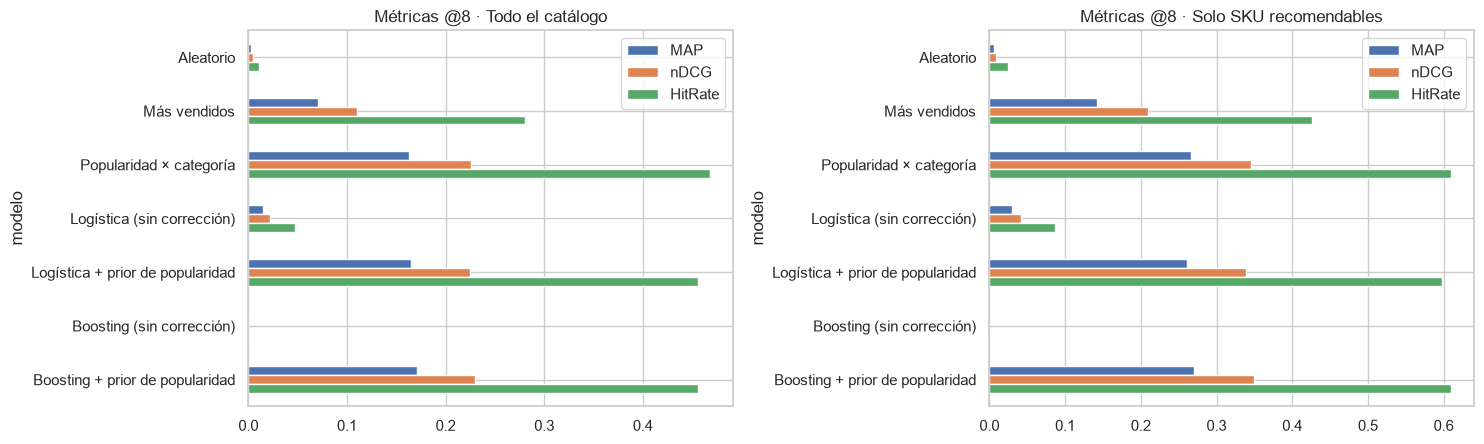

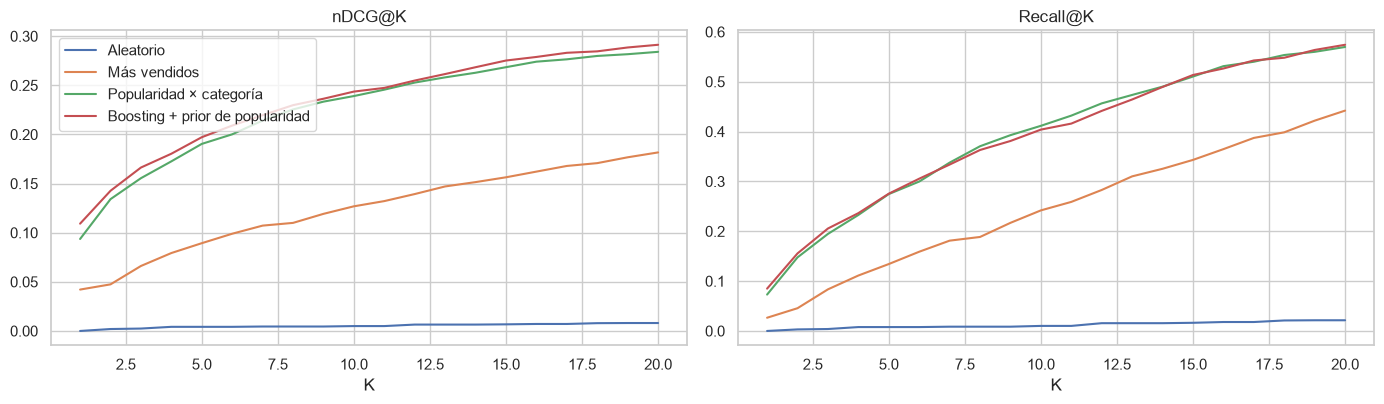

In [7]:
# Comparación visual (K = 8, todo el catálogo y solo recomendables)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for a, vista in zip(ax, VISTAS):
    t = tablas[vista]
    t = t[t["K"] == 8].set_index("modelo")[["MAP", "nDCG", "HitRate"]]
    t.plot.barh(ax=a)
    a.set_title(f"Métricas @8 · {vista}")
    a.invert_yaxis()
plt.tight_layout(); plt.show()

# Curvas métrica vs K para los baselines y el mejor modelo (todo el catálogo)
nombres_curva = ["Aleatorio", "Más vendidos", "Popularidad × categoría", "Boosting + prior de popularidad"]
curvas = {n: metricas_por_usuario(ranking, {**scores_baseline, **scores_modelo}[n], ks=tuple(range(1, K_CURVA + 1)))
          for n in nombres_curva}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for n, r in curvas.items():
    ax[0].plot(range(1, K_CURVA + 1), [r[k]["ndcg"].mean() for k in range(1, K_CURVA + 1)], label=n)
    ax[1].plot(range(1, K_CURVA + 1), [r[k]["recall"].mean() for k in range(1, K_CURVA + 1)], label=n)
ax[0].set_title("nDCG@K"); ax[1].set_title("Recall@K")
for a in ax: a.set_xlabel("K")
ax[0].legend(); plt.tight_layout(); plt.show()

### 5.1 ¿La diferencia es real o ruido?
Con pocos usuarios, una diferencia pequeña puede ser azar. Se estima un **intervalo de confianza del 95%** para la diferencia de nDCG@8 entre cada modelo y el **mejor baseline**, remuestreando usuarios con bootstrap pareado.

In [8]:
def bootstrap_diferencia(a, b, n_boot=N_BOOT, seed=RANDOM_STATE):
    # a, b: valores por usuario (mismo orden). Devuelve diferencia media e IC 95%.
    rng_b = np.random.default_rng(seed)
    d = np.asarray(a) - np.asarray(b)
    idx = rng_b.integers(0, len(d), size=(n_boot, len(d)))
    medias = d[idx].mean(axis=1)
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)


baselines = ["Aleatorio", "Más vendidos", "Popularidad × categoría"]
conclusion = {}
for vista in VISTAS:
    t8 = tablas[vista][tablas[vista]["K"] == 8].set_index("modelo")
    mejor_base = t8.loc[baselines, "nDCG"].idxmax()
    filas = []
    for nombre in [n for n in res[vista] if n not in baselines]:
        for metrica in ["ndcg", "map"]:
            d, lo, hi = bootstrap_diferencia(res[vista][nombre][8][metrica], res[vista][mejor_base][8][metrica])
            filas.append({"modelo": nombre, "métrica@8": metrica, "diferencia vs mejor baseline": d,
                          "IC95% inferior": lo, "IC95% superior": hi, "significativa": (lo > 0) or (hi < 0)})
    tb = pd.DataFrame(filas)
    conclusion[vista] = (mejor_base, tb)
    print(f"\n=== {vista} · mejor baseline: {mejor_base} ===")
    display(tb.set_index(["modelo", "métrica@8"]))


=== Todo el catálogo · mejor baseline: Popularidad × categoría ===


diferencia vs mejor baseline  IC95% inferior  IC95% superior  significativa
modelo                           métrica@8                                                                             
Logística (sin corrección)       ndcg                            -0.2040         -0.2251         -0.1821           True
                                 map                             -0.1478         -0.1673         -0.1286           True
Logística + prior de popularidad ndcg                            -0.0004         -0.0099          0.0091          False
                                 map                              0.0024         -0.0072          0.0123          False
Boosting (sin corrección)        ndcg                            -0.2254         -0.2478         -0.2018           True
                                 map                             -0.1630         -0.1825         -0.1423           True
Boosting + prior de popularidad  ndcg                             0.0044         -0.0062          0.0151          False
                                 map                              0.0080         -0.0026          0.0190          False


=== Solo SKU recomendables · mejor baseline: Popularidad × categoría ===


diferencia vs mejor baseline  IC95% inferior  IC95% superior  significativa
modelo                           métrica@8                                                                             
Logística (sin corrección)       ndcg                            -0.3040         -0.3380         -0.2690           True
                                 map                             -0.2362         -0.2689         -0.2033           True
Logística + prior de popularidad ndcg                            -0.0077         -0.0228          0.0071          False
                                 map                             -0.0054         -0.0219          0.0115          False
Boosting (sin corrección)        ndcg                            -0.3460         -0.3812         -0.3088           True
                                 map                             -0.2660         -0.2997         -0.2317           True
Boosting + prior de popularidad  ndcg                             0.0035         -0.0098          0.0176          False
                                 map                              0.0048         -0.0107          0.0204          False

## 6. Análisis

### 6.1 Por tipo de usuario
¿Para quién aporta el modelo? Se separa a los usuarios por cantidad de pedidos previos al corte (más historial = más información para personalizar).

In [9]:
mejor_nombre = tablas["Todo el catálogo"].query("K == 8").sort_values("nDCG", ascending=False).iloc[0]["modelo"]
if mejor_nombre in baselines:      # si ningún modelo supera a los baselines, igual se analiza el mejor modelo entrenado
    mejor_nombre = tablas["Todo el catálogo"].query("K == 8 and modelo not in @baselines").sort_values("nDCG", ascending=False).iloc[0]["modelo"]
print(f"Modelo analizado: {mejor_nombre}")

n_ped = ranking.groupby("usuario_id")["n_pedidos"].first()
tramo = pd.cut(n_ped, [0, 1, 3, 6, np.inf], labels=["1 pedido", "2–3 pedidos", "4–6 pedidos", "7 o más"])
base_name = conclusion["Todo el catálogo"][0]
seg = pd.DataFrame({
    "usuarios": res["Todo el catálogo"][mejor_nombre][8]["ndcg"].groupby(tramo.reindex(res["Todo el catálogo"][mejor_nombre][8].index)).size(),
    f"nDCG@8 {mejor_nombre}": res["Todo el catálogo"][mejor_nombre][8]["ndcg"].groupby(tramo.reindex(res["Todo el catálogo"][mejor_nombre][8].index)).mean(),
    f"nDCG@8 {base_name}": res["Todo el catálogo"][base_name][8]["ndcg"].groupby(tramo.reindex(res["Todo el catálogo"][base_name][8].index)).mean(),
})
display(seg)

Modelo analizado: Boosting + prior de popularidad


,usuarios,nDCG@8 Boosting + prior de popularidad,nDCG@8 Popularidad × categoría
n_pedidos,,,
1 pedido,106,0.2132,0.2125
2–3 pedidos,316,0.2448,0.2432
4–6 pedidos,192,0.2101,0.1986
7 o más,27,0.2594,0.2590


### 6.2 Cola larga y diversidad
El caso advierte que la mayor parte de las ventas se concentra en pocos SKU y que la cola larga no se descubre (R7). Se mide qué fracción de las recomendaciones sale de la **cola** (los SKU fuera del 80% de las ventas) y cuántos SKU distintos se recomiendan.

In [10]:
ventas_sku = ranking.drop_duplicates("sku").set_index("sku")["unidades_vendidas"].sort_values(ascending=False)
acum = ventas_sku.cumsum() / ventas_sku.sum()
cabeza = set(acum[acum <= 0.80].index) | {acum.index[0]}
print(f"SKU de la 'cabeza' (concentran el 80% de las unidades vendidas antes del corte): {len(cabeza)} de {len(ventas_sku)}")

def cobertura(score, solo_rec=False, k=8):
    d = ranking[["usuario_id", "sku", "recomendable"]].copy()
    d["score"] = np.asarray(score, float)
    if solo_rec: d = d[d["recomendable"]]
    top = (d.sort_values(["usuario_id", "score", "sku"], ascending=[True, False, True], kind="mergesort")
             .groupby("usuario_id").head(k))
    return {"SKU distintos recomendados": top["sku"].nunique(),
            "% del catálogo recomendado": 100 * top["sku"].nunique() / d["sku"].nunique(),
            "% de recomendaciones de la cola larga": 100 * (~top["sku"].isin(cabeza)).mean()}

todos_scores = {**scores_baseline, **scores_modelo}
cob = pd.DataFrame({n: cobertura(todos_scores[n]) for n in
                    ["Más vendidos", "Popularidad × categoría", "Logística + prior de popularidad",
                     "Boosting (sin corrección)", "Boosting + prior de popularidad"]}).T
display(cob)

SKU de la 'cabeza' (concentran el 80% de las unidades vendidas antes del corte): 51 de 1500


,SKU distintos recomendados,% del catálogo recomendado,% de recomendaciones de la cola larga
Más vendidos,14.0000,0.9333,0.0000
Popularidad × categoría,40.0000,2.6667,0.4095
Logística + prior de popularidad,38.0000,2.5333,0.0000
Boosting (sin corrección),167.0000,11.1333,100.0000
Boosting + prior de popularidad,38.0000,2.5333,0.0000


### 6.3 Qué variables importan
Importancia por permutación sobre los pares de validación: cuánto cae la *Average Precision* al desordenar cada variable. Es una importancia **global**, útil para entender el modelo; la explicación individual está en 6.4.

,variable,caida_AP,desv
0,afinidad_categoria,0.1490,0.0045
1,n_compradores,0.0165,0.0016
2,categoria,0.0128,0.0032
3,unidades_vendidas,0.0090,0.0034
4,senal_implicita,0.0075,0.0004
5,compradores_90d,0.0052,0.0009
6,regla_pop_categoria,0.0050,0.0027
7,precio_lista,0.0007,0.0004
8,unidades_totales,0.0006,0.0006
9,afinidad_marca,0.0004,0.0002


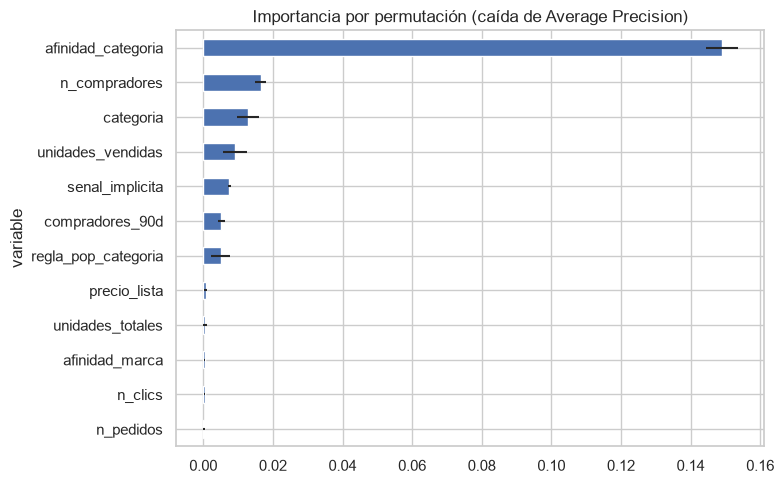

In [11]:
m_imp = modelos["Boosting"]
muestra = validacion.sample(min(len(validacion), 4000), random_state=RANDOM_STATE)
imp = permutation_importance(m_imp, muestra[FEATURES], muestra["compra"], scoring="average_precision",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
tabla_imp = (pd.DataFrame({"variable": FEATURES, "caida_AP": imp.importances_mean, "desv": imp.importances_std})
             .sort_values("caida_AP", ascending=False).reset_index(drop=True))
display(tabla_imp.head(12))
fig, ax = plt.subplots(figsize=(8, 5))
tabla_imp.head(12).iloc[::-1].plot.barh(x="variable", y="caida_AP", xerr="desv", ax=ax, legend=False)
ax.set_title("Importancia por permutación (caída de Average Precision)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 6.4 Explicación de cada recomendación (RN3: derecho a explicación)
El cliente puede pedir saber por qué se le recomendó algo. Se genera una explicación en lenguaje simple a partir de las señales del propio par usuario–producto.

In [12]:
def explicar_recomendacion(fila, umbral_pop=0.9, cuantil_pop=None):
    # Razones legibles a partir de los predictores del par. No usa información sensible.
    razones = []
    if fila["afinidad_categoria"] >= 0.30:
        razones.append(f"compras con frecuencia en la categoría {fila['categoria']}")
    if fila["afinidad_marca"] >= 0.30 and fila["marca"] != "sin_dato":
        razones.append(f"sueles comprar la marca {fila['marca']}")
    if fila["n_agregados_carrito"] > 0:
        razones.append("lo agregaste al carrito antes")
    elif fila["n_vistas"] > 0 or fila["n_clics"] > 0:
        razones.append("lo viste recientemente")
    if cuantil_pop is not None and fila["n_compradores"] >= cuantil_pop:
        razones.append("es de los productos más comprados")
    return razones or ["es popular entre clientes con compras parecidas a las tuyas"]


CUANTIL_POP = ranking.drop_duplicates("sku")["n_compradores"].quantile(0.9)
nombres = productos.set_index("sku")["nombre"].to_dict()


def recomendar(candidatos, puntaje, k=8, solo_recomendables=True):
    # Top-k por usuario (sin lo ya comprado: el grid de candidatos ya lo excluye).
    d = candidatos.copy()
    d["puntaje"] = np.asarray(puntaje, float)
    if solo_recomendables:
        d = d[d["recomendable"]]
    d = d.sort_values(["usuario_id", "puntaje", "sku"], ascending=[True, False, True], kind="mergesort")
    return d.groupby("usuario_id").head(k)


top = recomendar(ranking, scores_modelo["Boosting + prior de popularidad"], k=5)
ejemplo = top["usuario_id"].iloc[0]
vista_ej = top[top["usuario_id"] == ejemplo].copy()
vista_ej["producto"] = vista_ej["sku"].map(nombres).fillna("(sin nombre en catálogo)")
vista_ej["por qué"] = vista_ej.apply(lambda f: "; ".join(explicar_recomendacion(f, cuantil_pop=CUANTIL_POP)), axis=1)
print(f"Recomendaciones de ejemplo para {ejemplo}:")
display(vista_ej[["sku", "producto", "categoria", "puntaje", "compra", "por qué"]])

Recomendaciones de ejemplo para U100013:


,sku,producto,categoria,puntaje,compra,por qué
344543,NX-11144,LG Cables y adaptadore Pro,cables y adaptadores,4.9325,0,compras con frecuencia en la categoría cables ...
344348,NX-11040,Kingston Notebook X,notebooks,4.6151,0,es de los productos más comprados
345005,NX-10899,Corsair Gaming Plus,gaming,4.2085,0,es de los productos más comprados
344545,NX-11142,(sin nombre en catálogo),gaming,4.1499,0,es de los productos más comprados
344626,NX-10456,Apple Gaming Air,gaming,4.0291,0,es de los productos más comprados


## 7. Modelo final y entregables
Se elige el mejor modelo entrenado (por nDCG@8 en todo el catálogo) y se **reentrena con todos los cortes disponibles, incluido el de validación**, que es lo que se usaría en producción. También se guarda la lista de **más vendidos recomendables**, que es el plan B del RNF3 si el servicio no responde a tiempo.

In [13]:
t8 = tablas["Todo el catálogo"].query("K == 8 and modelo not in @baselines").sort_values("nDCG", ascending=False)
nombre_final = t8.iloc[0]["modelo"]
familia = "Boosting" if nombre_final.startswith("Boosting") else "Logística"
usa_prior = "prior" in nombre_final
print(f"Modelo final: {familia} {'con' if usa_prior else 'sin'} corrección de popularidad")

todo = pd.concat([entrenamiento, validacion], ignore_index=True)
if familia == "Boosting":
    modelo_final = pipeline_boosting(**mejor["boosting"])
else:
    modelo_final = pipeline_logistica(**mejor["logística"])
modelo_final.fit(todo[FEATURES], todo["compra"])

# Plan B (RNF3): más vendidos recomendables en los últimos 90 días de datos
trx = pd.read_csv(OUT_DIR / "transacciones_limpio.csv", parse_dates=["fecha_dt"])
fin = metadatos["fin_datos"]
recientes = trx[trx["fecha_dt"] >= fin - pd.Timedelta(days=metadatos["horizonte_dias"])]
mas_vendidos = (recientes[recientes["sku"].isin(sku_recomendables)].groupby("sku")["cantidad"].sum()
                .sort_values(ascending=False).head(50))

metadatos_modelo = {
    "familia": familia, "usa_prior_popularidad": usa_prior, "pop_alpha": POP_ALPHA, "eps_pop": EPS_POP,
    "features": FEATURES, "cols_cat": COLS_CAT, "cols_num": COLS_NUM,
    "hiperparametros": mejor["boosting"] if familia == "Boosting" else mejor["logística"],
    "metricas_validacion": tablas, "ks": KS, "corte_validacion": metadatos["corte_validacion"],
    "random_state": RANDOM_STATE,
    "versiones": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
    "uso": ("puntaje = modelo.decision_function(X[features]) + pop_alpha*log(n_compradores + eps_pop) si usa_prior; "
            "ordenar por puntaje, excluir lo ya comprado y filtrar a SKU recomendables al servir"),
}
joblib.dump(modelo_final, MODEL_DIR / "modelo_recomendador.joblib")
joblib.dump(metadatos_modelo, MODEL_DIR / "modelo_metadatos.joblib")
joblib.dump(mas_vendidos, MODEL_DIR / "fallback_mas_vendidos.joblib")

# Comprobación: el modelo guardado se carga y reproduce los puntajes
recargado = joblib.load(MODEL_DIR / "modelo_recomendador.joblib")
assert np.allclose(recargado.decision_function(ranking[FEATURES].head(500)),
                   modelo_final.decision_function(ranking[FEATURES].head(500)))
print(f"[PASS] el modelo guardado se recarga y reproduce los puntajes")
print(f"Entregables en {MODEL_DIR}:")
for _f in sorted(MODEL_DIR.iterdir()):
    print(f"  {_f.name:30s} {_f.stat().st_size:>10,} bytes")

Modelo final: Boosting con corrección de popularidad
[PASS] el modelo guardado se recarga y reproduce los puntajes
Entregables en C:\Users\Gabo\Documents\modelo-nexus arquitectura\modelo-nexus\datos\modelos:
  fallback_mas_vendidos.joblib        3,202 bytes
  modelo_metadatos.joblib             5,337 bytes
  modelo_recomendador.joblib        157,705 bytes


## 8. Conclusiones

In [14]:
for vista in VISTAS:
    mejor_base, tb = conclusion[vista]
    t8 = tablas[vista][tablas[vista]["K"] == 8].set_index("modelo")
    print(f"\n=== {vista} ===")
    print(f"Mejor baseline: {mejor_base} (nDCG@8 = {t8.loc[mejor_base, 'nDCG']:.4f}, MAP@8 = {t8.loc[mejor_base, 'MAP']:.4f})")
    cand = t8.drop(index=baselines)["nDCG"].sort_values(ascending=False)
    mejor_m = cand.index[0]
    fila = tb[(tb["modelo"] == mejor_m) & (tb["métrica@8"] == "ndcg")].iloc[0]
    print(f"Mejor modelo: {mejor_m} (nDCG@8 = {cand.iloc[0]:.4f}, MAP@8 = {t8.loc[mejor_m, 'MAP']:.4f}, HitRate@8 = {t8.loc[mejor_m, 'HitRate']:.3f})")
    fm = tb[(tb["modelo"] == mejor_m) & (tb["métrica@8"] == "map")].iloc[0]
    print(f"Diferencia de MAP@8 frente al baseline: {fm['diferencia vs mejor baseline']:+.4f} "
          f"(IC95% {fm['IC95% inferior']:+.4f} a {fm['IC95% superior']:+.4f}) -> "
          f"{'significativa' if fm['significativa'] else 'no significativa'}")
    print(f"Diferencia de nDCG@8 frente al baseline: {fila['diferencia vs mejor baseline']:+.4f} "
          f"(IC95% {fila['IC95% inferior']:+.4f} a {fila['IC95% superior']:+.4f}) -> "
          f"{'SUPERA al baseline de forma significativa' if fila['diferencia vs mejor baseline'] > 0 and fila['significativa'] else ('NO supera al baseline' if fila['diferencia vs mejor baseline'] <= 0 and fila['significativa'] else 'diferencia NO concluyente (puede ser ruido)')}")


=== Todo el catálogo ===
Mejor baseline: Popularidad × categoría (nDCG@8 = 0.2254, MAP@8 = 0.1630)
Mejor modelo: Boosting + prior de popularidad (nDCG@8 = 0.2298, MAP@8 = 0.1710, HitRate@8 = 0.456)
Diferencia de MAP@8 frente al baseline: +0.0080 (IC95% -0.0026 a +0.0190) -> no significativa
Diferencia de nDCG@8 frente al baseline: +0.0044 (IC95% -0.0062 a +0.0151) -> diferencia NO concluyente (puede ser ruido)

=== Solo SKU recomendables ===
Mejor baseline: Popularidad × categoría (nDCG@8 = 0.3460, MAP@8 = 0.2660)
Mejor modelo: Boosting + prior de popularidad (nDCG@8 = 0.3495, MAP@8 = 0.2708, HitRate@8 = 0.610)
Diferencia de MAP@8 frente al baseline: +0.0048 (IC95% -0.0107 a +0.0204) -> no significativa
Diferencia de nDCG@8 frente al baseline: +0.0035 (IC95% -0.0098 a +0.0176) -> diferencia NO concluyente (puede ser ruido)


### Cómo leer los resultados
- Con un catálogo de unos 1.500 SKU y compras muy repartidas, los valores absolutos de MAP y nDCG son **bajos**. Lo que importa es la **comparación** con los baselines y el intervalo de confianza.
- Una mejora en el modelo **sin** corrección de popularidad que desaparece al rankear todo el catálogo indica que el modelo aprendió preferencias pero perdió el prior de popularidad; la versión **con** corrección lo recupera.
- Las métricas son *offline*: miden qué tan bien se habrían ordenado compras pasadas. El criterio de éxito del caso es la **conversión en el piloto** (+0,5 puntos porcentuales frente al grupo sin recomendaciones), que solo se mide en producción.

### Limitaciones
- **Pocos datos de comportamiento:** solo una parte de los positivos tiene clics o vistas previas, por lo que el modelo se apoya sobre todo en compras e información del producto.
- **Consentimiento:** se entrenó solo con usuarios que aceptaron; no se sabe si su comportamiento es representativo del resto.
- **`activo` y `stock` poco confiables:** gran parte de las compras recientes corresponde a SKU hoy "no recomendables". La vista *Solo SKU recomendables* muestra el desempeño bajo ese filtro.
- **Una sola ventana de validación** (90 días): los resultados pueden cambiar con otro periodo.
- **Cold start:** los usuarios sin historial no se evalúan; para ellos se usa el plan B de más vendidos (RF8 / RNF3).